# Engagement 1 · Student Performance EDA for the County Education Office

**Client:** County Director of Education  **Decision:** where to target a learner-support programme  
**Data:** `student_performance.csv` — 1,200 students, generated by `generate_data.py` (seed 55)

**Question:** Which learners are most at risk of poor performance, and which factors are associated with better results?

The notebook follows the five-step EDA framework: **1. Structure → 2. Univariate → 3. Bivariate → 4. Multivariate → 5. Hypotheses**, and closes with **Findings**, **Recommendations** and **Limitations**.

*To reproduce: run `python generate_data.py`, then restart the kernel and run all cells from top to bottom. Charts are saved to `figures/`.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("figures", exist_ok=True)
if not os.path.exists("student_performance.csv"):
    raise FileNotFoundError("Run `python generate_data.py` first to create student_performance.csv")

students = pd.read_csv("student_performance.csv")

## 1. Structure

**Grain:** one row = one student, observed once. There is **no date column**, so this is a cross-section (a single snapshot), not a time series. That is why Task 7 fits a trend line against `study_hours` rather than against time.

In [2]:
print("Shape:", students.shape)
students.head()

Shape: (1200, 9)


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [3]:
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   int64  
 1   county           1200 non-null   str    
 2   school_type      1200 non-null   str    
 3   gender           1200 non-null   str    
 4   attendance_rate  1200 non-null   float64
 5   study_hours      1200 non-null   float64
 6   math             1200 non-null   float64
 7   english          1200 non-null   float64
 8   science          1200 non-null   float64
dtypes: float64(5), int64(1), str(3)
memory usage: 84.5 KB


### Variables and their types

| Variable | What it holds | Type |
|---|---|---|
| `student_id` | Unique learner number 1–1,200 | Identifier (nominal, not analysed numerically) |
| `county` | Nairobi, Kisumu, Nakuru, Mombasa, Nyeri, Turkana | Categorical, nominal |
| `school_type` | Public or Private | Categorical, nominal (binary) |
| `gender` | F or M | Categorical, nominal (binary) |
| `attendance_rate` | Share of school days attended, 0–1 | Numerical, continuous |
| `study_hours` | Study hours per week | Numerical, continuous |
| `math`, `english`, `science` | Subject marks, whole numbers 0–100 | Numerical (whole-number marks, treated as continuous) |
| `average_score` *(derived below)* | Mean of the three subject marks | Numerical, continuous |
| `performance_band` *(derived below)* | At Risk / Meeting / Exceeding | Categorical, **ordinal** |

`student_id` is a label, so averaging it would be meaningless; it is excluded from all statistics.

In [4]:
# Data-quality checks
print("Missing values per column:\n", students.isna().sum().to_string(), sep="")
print("\nDuplicate rows:", students.duplicated().sum())
print("student_id unique:", students["student_id"].is_unique)
print("attendance_rate within 0-1:", students["attendance_rate"].between(0, 1).all())
print("study_hours all >= 0:", (students["study_hours"] >= 0).all())
print("Subject marks within 0-100:", students[["math", "english", "science"]].apply(lambda c: c.between(0, 100).all()).all())
for col in ["county", "school_type", "gender"]:
    print(f"{col}: {sorted(students[col].unique())}")
print("\nMarks at the 100 ceiling:", (students[["math", "english", "science"]] == 100).sum().to_dict())

Missing values per column:
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0

Duplicate rows: 0
student_id unique: True
attendance_rate within 0-1: True
study_hours all >= 0: True
Subject marks within 0-100: True
county: ['Kisumu', 'Mombasa', 'Nairobi', 'Nakuru', 'Nyeri', 'Turkana']
school_type: ['Private', 'Public']
gender: ['F', 'M']

Marks at the 100 ceiling: {'math': 11, 'english': 21, 'science': 16}


**Data-quality verdict:** no missing values, no duplicate rows, unique IDs, every value inside its valid range and consistent category labels. The only feature to remember is that marks are capped at 100 (11 maths, 21 English and 16 science marks sit on the ceiling), which matters when a straight line is extrapolated in Section 3.

## 2. Univariate

### 2.1 Numerical variables: centre, spread and shape

In [5]:
num_cols = ["attendance_rate", "study_hours", "math", "english", "science"]
summary = pd.DataFrame({
    "mean": students[num_cols].mean(),
    "median": students[num_cols].median(),
    "std": students[num_cols].std(),
    "IQR": students[num_cols].quantile(0.75) - students[num_cols].quantile(0.25),
    "min": students[num_cols].min(),
    "max": students[num_cols].max(),
    "skew": students[num_cols].skew(),
}).round(2)
summary

,mean,median,std,IQR,min,max,skew
attendance_rate,0.80,0.82,0.12,0.17,0.33,1.0,-0.86
study_hours,5.08,4.50,3.03,3.80,0.20,23.3,1.17
math,71.89,72.00,10.86,14.00,37.00,100.0,0.10
english,74.52,74.00,10.49,14.00,47.00,100.0,0.16
science,69.61,69.00,12.02,17.00,35.00,100.0,0.11


**Reading the table**
- **`study_hours` is right-skewed** (skew 1.17): the mean (5.08) sits above the median (4.5) because a minority study far longer than the typical learner. The median is the better "typical" value.
- **`attendance_rate` is left-skewed** (skew -0.86): most learners attend most days, with a tail of low attenders. These are the learners to watch.
- **The three subject marks are close to symmetrical** (skew 0.10 to 0.16), with similar spread (std 10.5 to 12.0). English is the strongest subject (mean 74.5) and science the weakest (mean 69.6).

### 2.2 Outliers in `study_hours` (1.5 × IQR rule)

In [6]:
q1, q3 = students["study_hours"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = students[(students["study_hours"] < lower) | (students["study_hours"] > upper)]

print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}")
print(f"Fences: lower = {lower:.1f}, upper = {upper:.1f}")
print(f"Outliers: {len(outliers)} students ({len(outliers) / len(students):.1%}), "
      f"ranging from {outliers['study_hours'].min()} to {outliers['study_hours'].max()} hours")

Q1 = 2.9, Q3 = 6.7, IQR = 3.8
Fences: lower = -2.8, upper = 12.4
Outliers: 29 students (2.4%), ranging from 12.5 to 23.3 hours


29 learners (2.4%) study more than 12.4 hours a week, all on the high side (the lower fence is negative, so no low outliers). They are **plausible values from a long right tail, not data errors**, so they are kept. Section 3 checks how much they influence the trend line.

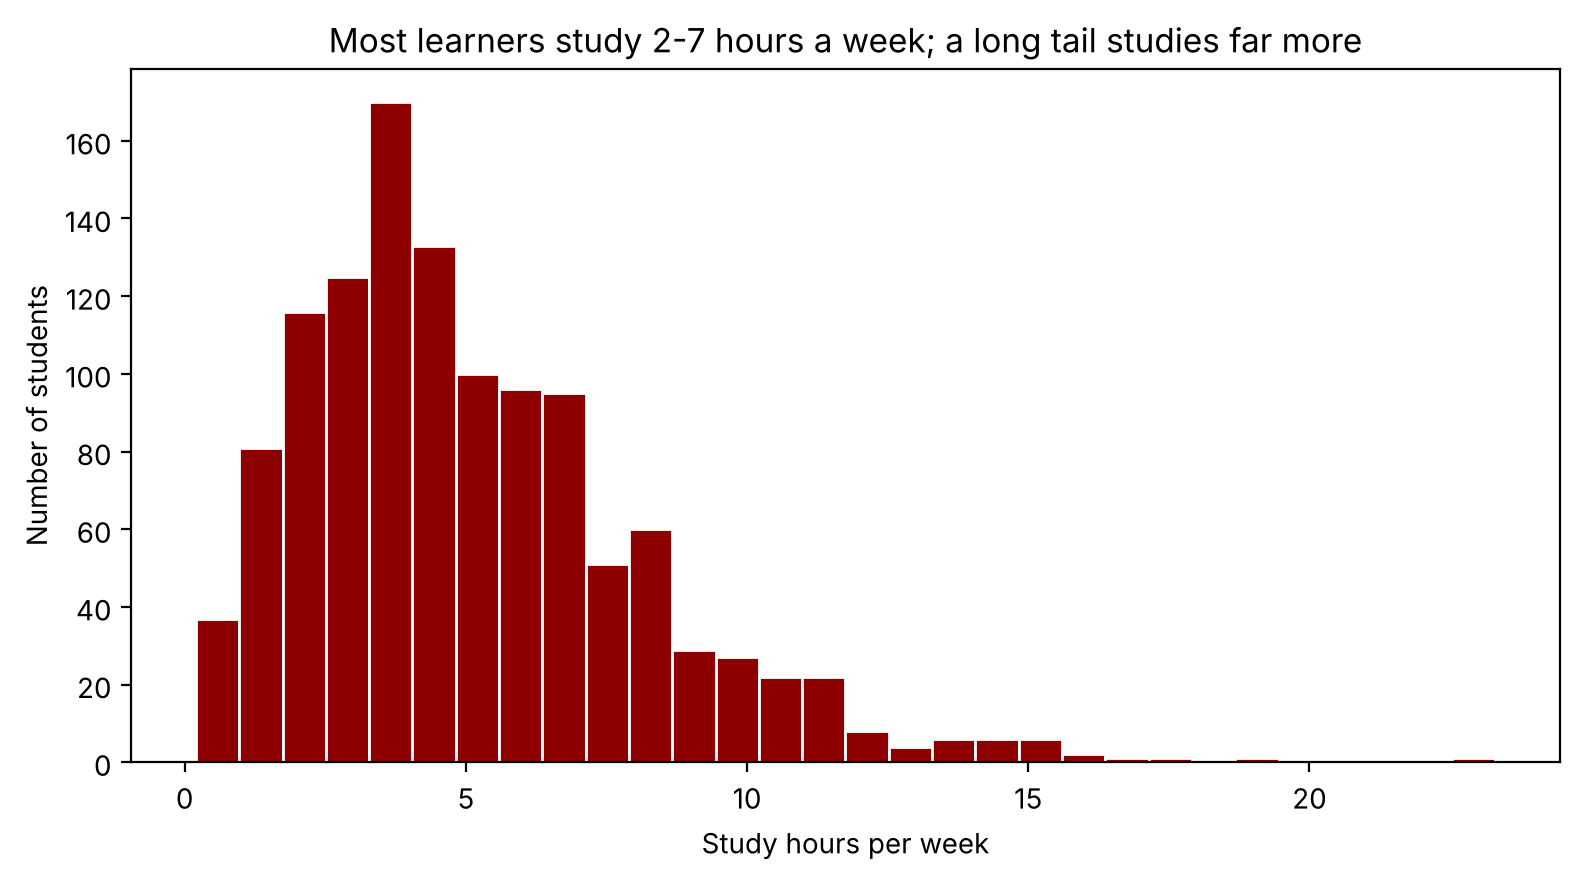

In [7]:
ax = students["study_hours"].plot(kind="hist", bins=30, color="#8E0000", edgecolor="white", figsize=(8, 4.5))
ax.set_title("Most learners study 2-7 hours a week; a long tail studies far more")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig("figures/01_study_hours_histogram.png", dpi=150)
plt.show()

**Shape:** right-skewed with a single peak near 3-4 hours and a long tail out to 23 hours. *(Saved as `figures/01_study_hours_histogram.png`.)*

### 2.3 Categorical variables: counts and shares

In [8]:
for col in ["county", "school_type", "gender"]:
    out = pd.DataFrame({"count": students[col].value_counts(),
                        "share": students[col].value_counts(normalize=True).round(3)})
    print(f"--- {col} ---")
    print(out, "\n")

--- county ---
         count  share
county               
Mombasa    212  0.177
Kisumu     208  0.173
Nyeri      203  0.169
Nakuru     202  0.168
Turkana    191  0.159
Nairobi    184  0.153 

--- school_type ---
             count  share
school_type              
Public         866  0.722
Private        334  0.278 

--- gender ---
        count  share
gender              
F         612   0.51
M         588   0.49 



Counties are fairly evenly represented (184 to 212 students each), gender is balanced, and about three in four students attend public schools. Group sizes are large enough to compare, though a single county has only around 200 learners.

### 2.4 Derived columns: `average_score` and `performance_band`

`performance_band` uses `pd.cut` with the brief's thresholds: **At Risk < 60, Meeting 60–74, Exceeding ≥ 75**. Because averages are not whole numbers (for example 74.67), the bins are `[0, 60)`, `[60, 75)` and `[75, 101)`.

In [9]:
students["average_score"] = students[["math", "english", "science"]].mean(axis=1).round(2)
students["performance_band"] = pd.cut(students["average_score"],
                                      bins=[0, 60, 75, 101],
                                      labels=["At Risk", "Meeting", "Exceeding"],
                                      right=False)

# helper flag used in later sections
students["at_risk"] = students["performance_band"].eq("At Risk")

print(students[["student_id", "math", "english", "science", "average_score", "performance_band"]].head())
print()
band = pd.DataFrame({"count": students["performance_band"].value_counts().sort_index(),
                     "share": students["performance_band"].value_counts(normalize=True).sort_index().round(3)})
print(band)
print()
print(students.groupby("performance_band", observed=True)["average_score"].agg(["min", "max"]).round(2))

   student_id   math  english  science  average_score performance_band
0           1   81.0     71.0     73.0           75.0        Exceeding
1           2  100.0     86.0     90.0           92.0        Exceeding
2           3   82.0     89.0     90.0           87.0        Exceeding
3           4   83.0     91.0     72.0           82.0        Exceeding
4           5   76.0     69.0     62.0           69.0          Meeting

                  count  share
performance_band              
At Risk              99  0.082
Meeting             672  0.560
Exceeding           429  0.358

                    min     max
performance_band               
At Risk           48.33   59.67
Meeting           60.00   74.67
Exceeding         75.00  100.00


**99 learners (8.2%) are At Risk**, 672 are Meeting expectations and 429 are Exceeding. The min/max check confirms the bands do not overlap. Because the At Risk group is small, the programme can be well targeted rather than universal.

## 3. Bivariate

### 3.1 Correlation matrix (numerical variables)

In [10]:
corr_cols = ["attendance_rate", "study_hours", "math", "english", "science", "average_score"]
pearson = students[corr_cols].corr().round(2)
spearman = students[corr_cols].corr(method="spearman").round(2)
print("Pearson:\n", pearson, "\n\nSpearman:\n", spearman, sep="")

Pearson:
                 attendance_rate  study_hours  math  english  science  \
attendance_rate             1.00        -0.03  0.30     0.33     0.26   
study_hours                -0.03         1.00  0.56     0.62     0.55   
math                        0.30         0.56  1.00     0.56     0.46   
english                     0.33         0.62  0.56     1.00     0.50   
science                     0.26         0.55  0.46     0.50     1.00   
average_score               0.36         0.70  0.81     0.83     0.82   

                 average_score  
attendance_rate           0.36  
study_hours               0.70  
math                      0.81  
english                   0.83  
science                   0.82  
average_score             1.00  

Spearman:
                 attendance_rate  study_hours  math  english  science  \
attendance_rate             1.00        -0.03  0.30     0.31     0.24   
study_hours                -0.03         1.00  0.52     0.58     0.51   
math              

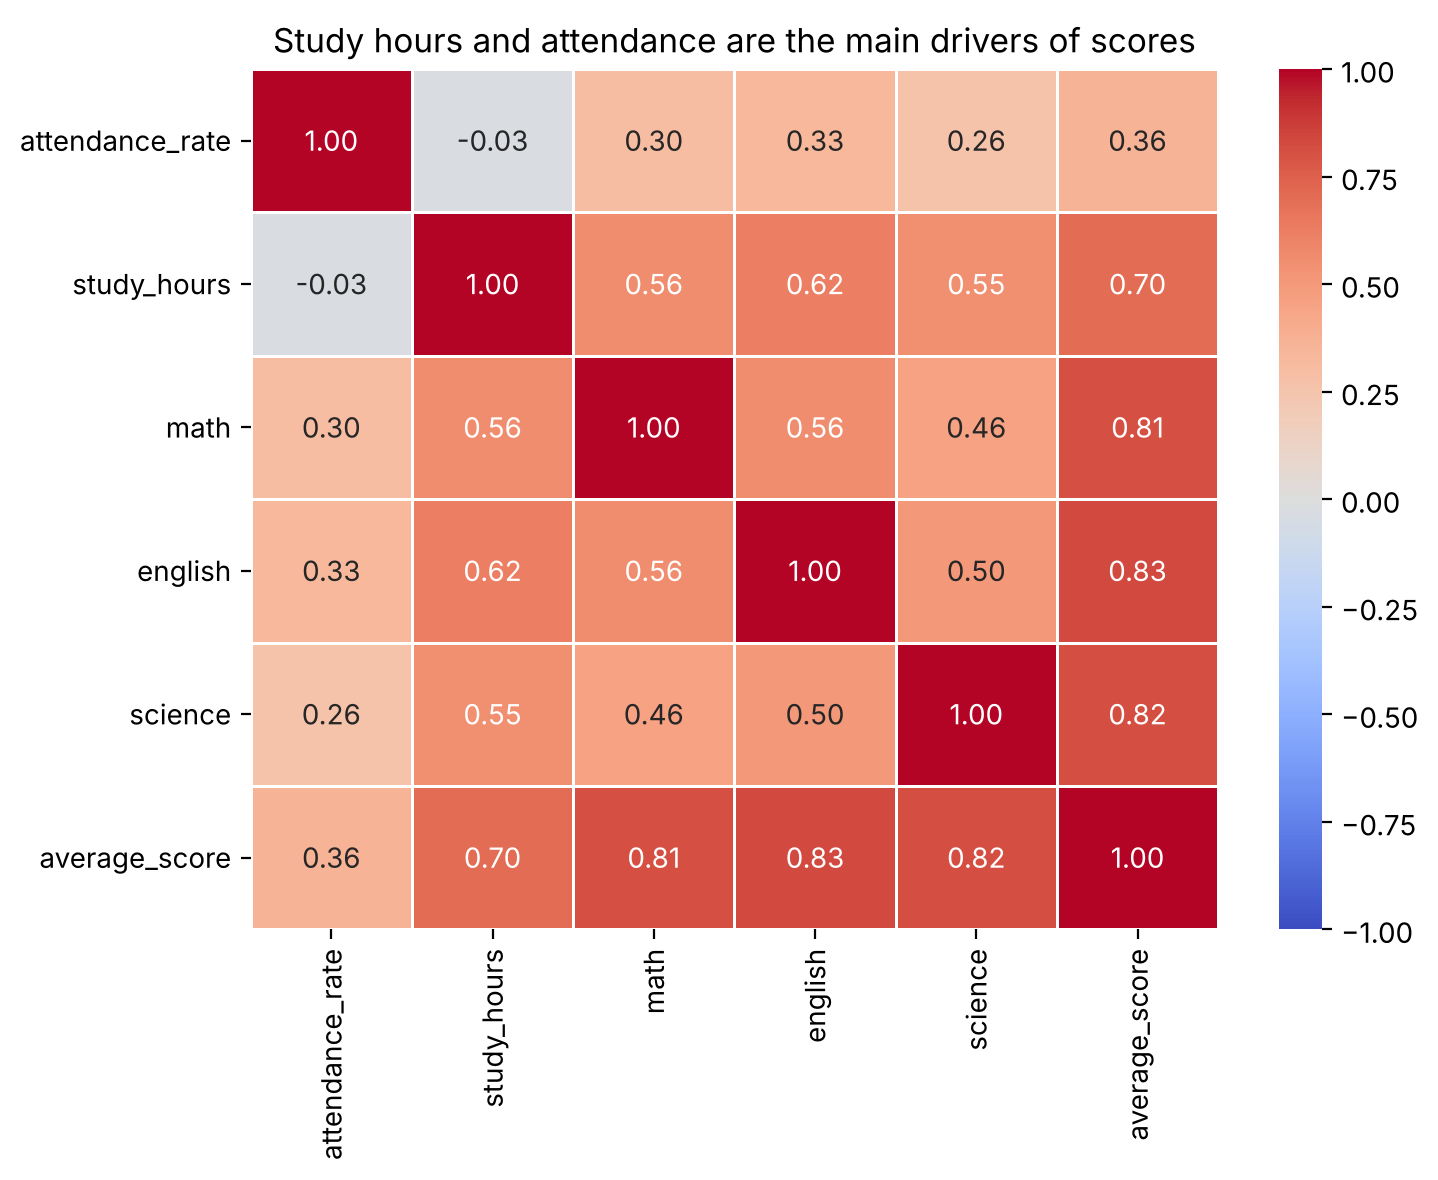

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Study hours and attendance are the main drivers of scores")
plt.tight_layout()
plt.savefig("figures/06_correlation_heatmap.png", dpi=150)
plt.show()

In [12]:
# Strongest relationships with average_score, plus school type as a 0/1 variable
with_score = pearson["average_score"].drop("average_score")
private_flag = (students["school_type"] == "Private").astype(int)
with_score["school_type (Private=1)"] = round(private_flag.corr(students["average_score"]), 2)
with_score.sort_values(ascending=False)

english                    0.83
science                    0.82
math                       0.81
study_hours                0.70
attendance_rate            0.36
school_type (Private=1)    0.27
Name: average_score, dtype: float64

**Three strongest relationships with `average_score`**

The three largest correlations are the subject marks themselves (English 0.83, science 0.82, maths 0.81). That is mechanical: `average_score` is built from them, so they are not insights. Among the genuine drivers, the three strongest are:

1. **`study_hours` (r = 0.70), strong positive.** Learners who study more hours score clearly higher. This is by far the strongest driver.
2. **`attendance_rate` (r = 0.36), moderate positive.** Higher attendance goes with higher scores, but the link is about half as strong as study hours.
3. **School type (r = 0.27), weak to moderate.** Private-school status is associated with higher scores (gender is essentially zero, r = 0.01).

Spearman correlations (ranks) give the same ordering (study hours 0.66, attendance 0.34), so the pattern is not caused by outliers. Study hours and attendance are almost uncorrelated with each other (r = -0.03), so each adds separate information. **These are associations, not proof that study hours or attendance cause higher scores.**

### 3.2 Average score by gender, school type and county

In [13]:
for col in ["gender", "school_type", "county"]:
    out = students.groupby(col)["average_score"].agg(["count", "mean", "median", "std"]).round(1)
    print(f"--- {col} ---")
    print(out.sort_values("mean", ascending=False), "\n")

--- gender ---
        count  mean  median  std
gender                          
F         612  72.1    71.7  9.2
M         588  71.9    71.3  9.0 

--- school_type ---
             count  mean  median  std
school_type                          
Private        334  76.0    75.3  8.1
Public         866  70.5    69.7  9.0 

--- county ---
         count  mean  median  std
county                           
Kisumu     208  73.1    72.5  9.5
Mombasa    212  72.2    72.2  8.4
Nairobi    184  72.0    72.2  9.3
Nyeri      203  71.9    71.3  9.1
Nakuru     202  71.8    70.8  9.0
Turkana    191  71.0    70.0  9.3 



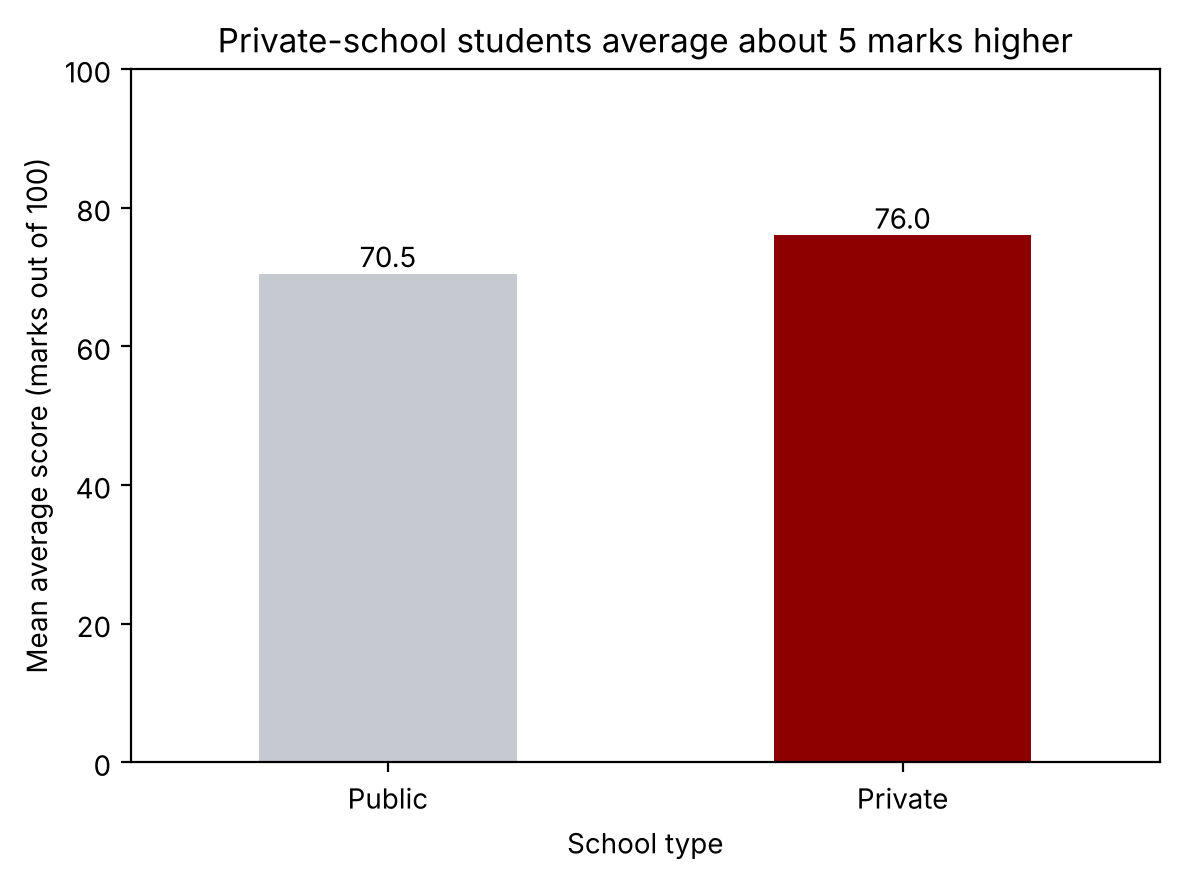

In [14]:
ax = (students.groupby("school_type")["average_score"].mean().sort_values()
      .plot(kind="bar", color=["#C7C9D1", "#8E0000"], figsize=(6, 4.5), rot=0))
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.set_ylim(0, 100)
ax.set_title("Private-school students average about 5 marks higher")
ax.set_xlabel("School type")
ax.set_ylabel("Mean average score (marks out of 100)")
plt.tight_layout()
plt.savefig("figures/02_avg_score_by_school_type_bar.png", dpi=150)
plt.show()

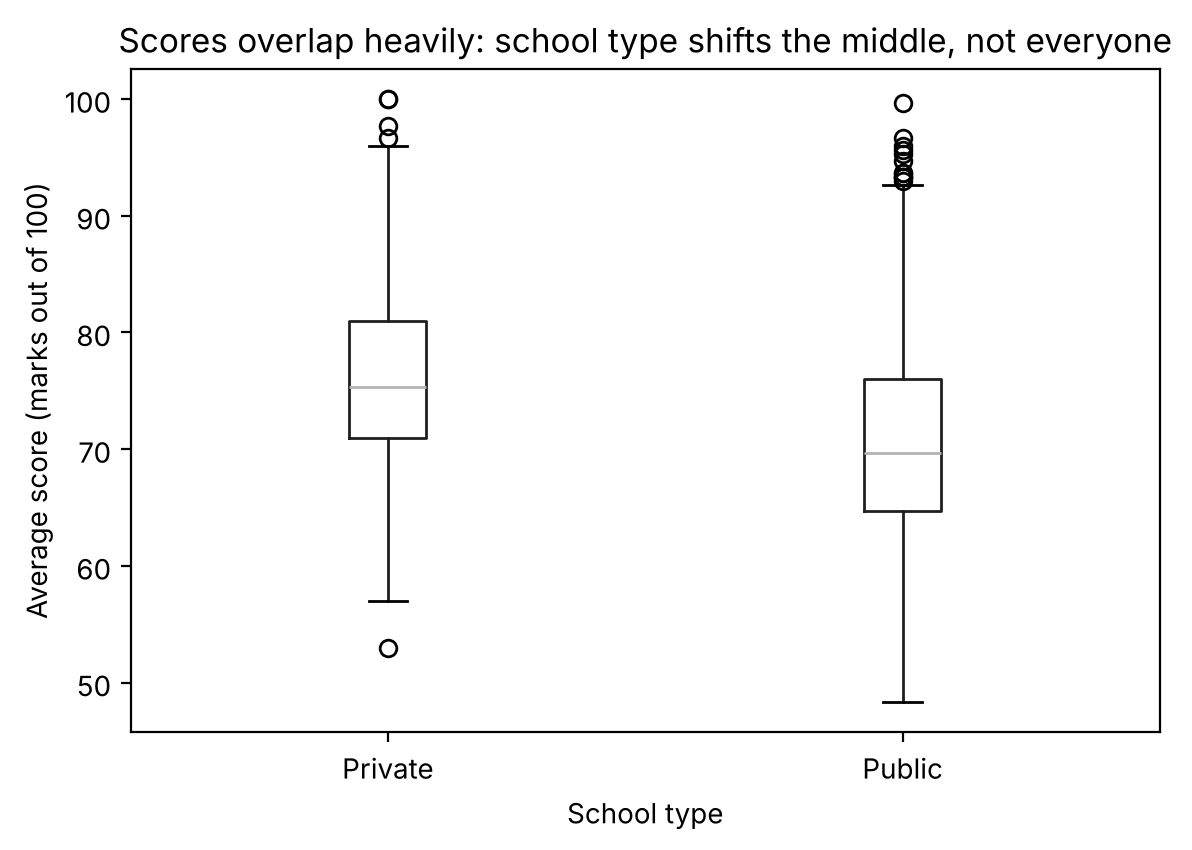

In [15]:
ax = students.boxplot(column="average_score", by="school_type", grid=False, figsize=(6, 4.5))
plt.suptitle("")
ax.set_title("Scores overlap heavily: school type shifts the middle, not everyone")
ax.set_xlabel("School type")
ax.set_ylabel("Average score (marks out of 100)")
plt.tight_layout()
plt.savefig("figures/03_avg_score_boxplot_by_school_type.png", dpi=150)
plt.show()

- **School type:** private 76.0 vs public 70.5, a gap of **5.5 marks**. The box plot shows the distributions overlap, so many public-school learners outperform many private-school learners.
- **Gender:** female 72.1 vs male 71.9, a gap of only 0.2 marks, which is negligible.
- **County:** averages range only from 71.0 (Turkana) to 73.1 (Kisumu), about 2.1 marks.

### 3.3 Which county has the highest share of At Risk learners?

In [16]:
county_band = pd.crosstab(students["county"], students["performance_band"], normalize="index").round(3)
county_band["n_students"] = students["county"].value_counts()
county_band = county_band.sort_values("At Risk", ascending=False)
print(county_band)

# Is the county difference bigger than chance? Chi-square test of county vs At Risk
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(students["county"], students["at_risk"]))
print(f"\nChi-square test, county vs At Risk: p = {p:.2f}")

performance_band  At Risk  Meeting  Exceeding  n_students
county                                                   
Nairobi             0.092    0.554      0.353         184
Mombasa             0.090    0.542      0.368         212
Nyeri               0.089    0.547      0.365         203
Kisumu              0.082    0.505      0.413         208
Turkana             0.079    0.597      0.325         191
Nakuru              0.064    0.619      0.317         202

Chi-square test, county vs At Risk: p = 0.92


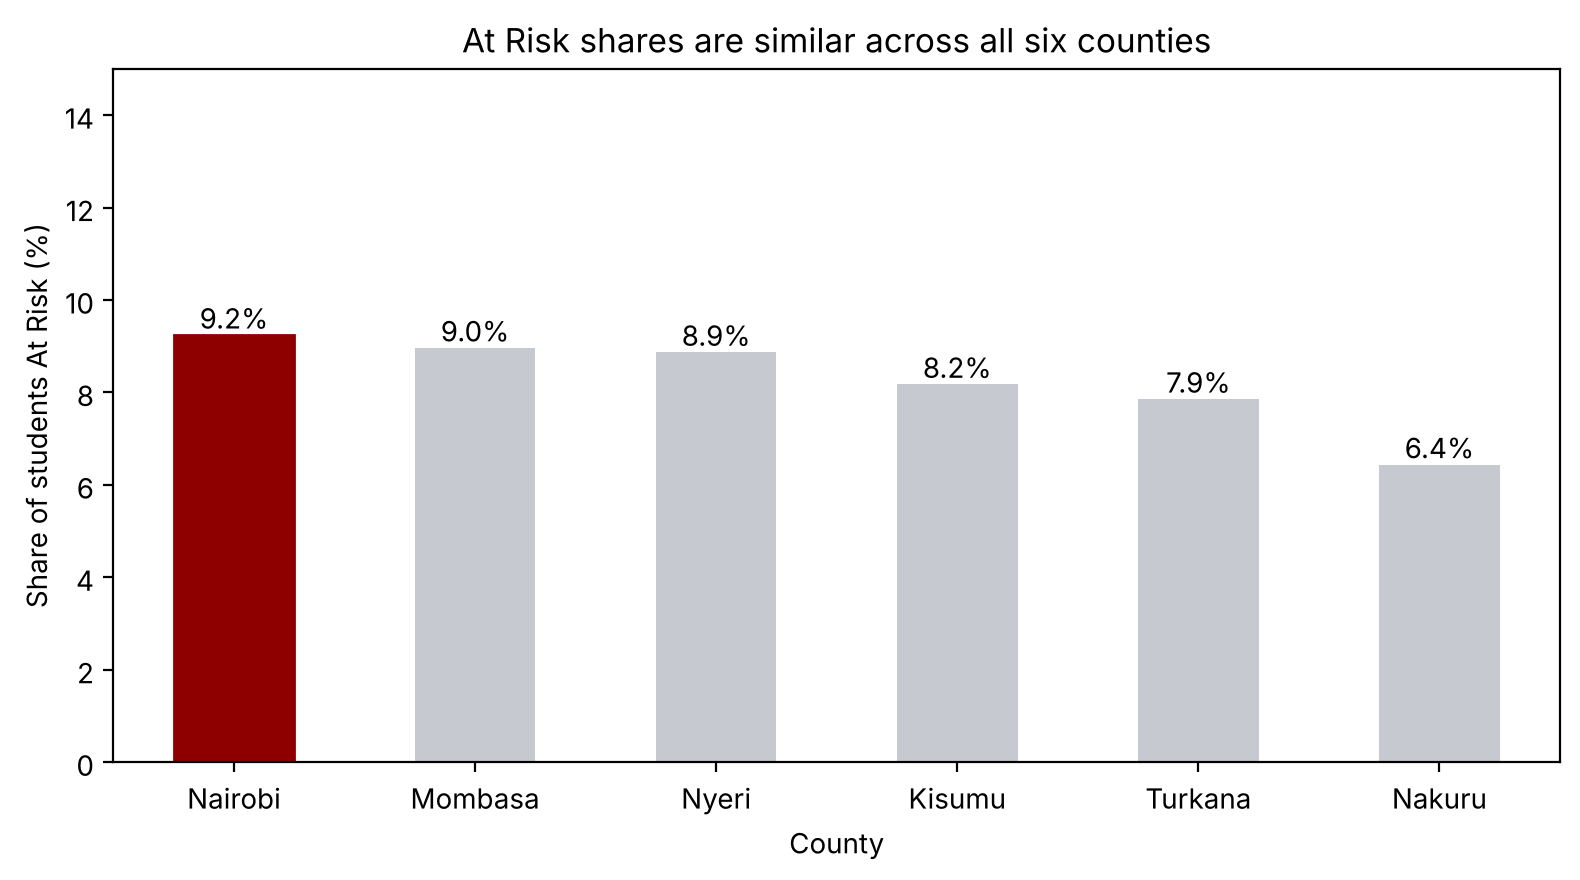

In [17]:
ax = ((students.groupby("county")["at_risk"].mean() * 100).sort_values(ascending=False)
      .plot(kind="bar", color="#C7C9D1", figsize=(8, 4.5), rot=0))
ax.patches[0].set_color("#8E0000")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylim(0, 15)
ax.set_title("At Risk shares are similar across all six counties")
ax.set_xlabel("County")
ax.set_ylabel("Share of students At Risk (%)")
plt.tight_layout()
plt.savefig("figures/04_at_risk_share_by_county_bar.png", dpi=150)
plt.show()

**Nairobi has the highest At Risk share at 9.2%** (17 of 184 students), followed by Mombasa (9.0%) and Nyeri (8.9%). The lowest is Nakuru (6.4%). However, the whole range is only 2.8 percentage points and a chi-square test gives p = 0.92, so these county differences are **well within what chance alone produces**. County is not a reliable basis for targeting.

### 3.4 Trend line: `average_score` against `study_hours`

In [18]:
x, y = students["study_hours"], students["average_score"]

slope, intercept = np.polyfit(x, y, 1)
r2 = stats.linregress(x, y).rvalue ** 2
print(f"average_score = {slope:.2f} x study_hours + {intercept:.2f}")
print(f"Slope = {slope:.2f} marks per extra weekly study hour, R-squared = {r2:.3f}")

# Limitation check: what does the line predict beyond the data?
print(f"\nObserved study hours: {x.min()} to {x.max()}")
print(f"Predicted score at 20 hours: {slope * 20 + intercept:.1f}  (impossible: marks are capped at 100)")
print(f"The line reaches 100 marks at {(100 - intercept) / slope:.1f} hours")

# Robustness: refit without the high study-hours outliers
trimmed = students[students["study_hours"] <= upper]
print(f"\nSlope without the {len(students) - len(trimmed)} outliers: {np.polyfit(trimmed['study_hours'], trimmed['average_score'], 1)[0]:.2f}")

average_score = 2.12 x study_hours + 61.26
Slope = 2.12 marks per extra weekly study hour, R-squared = 0.495

Observed study hours: 0.2 to 23.3
Predicted score at 20 hours: 103.6  (impossible: marks are capped at 100)
The line reaches 100 marks at 18.3 hours

Slope without the 29 outliers: 2.19


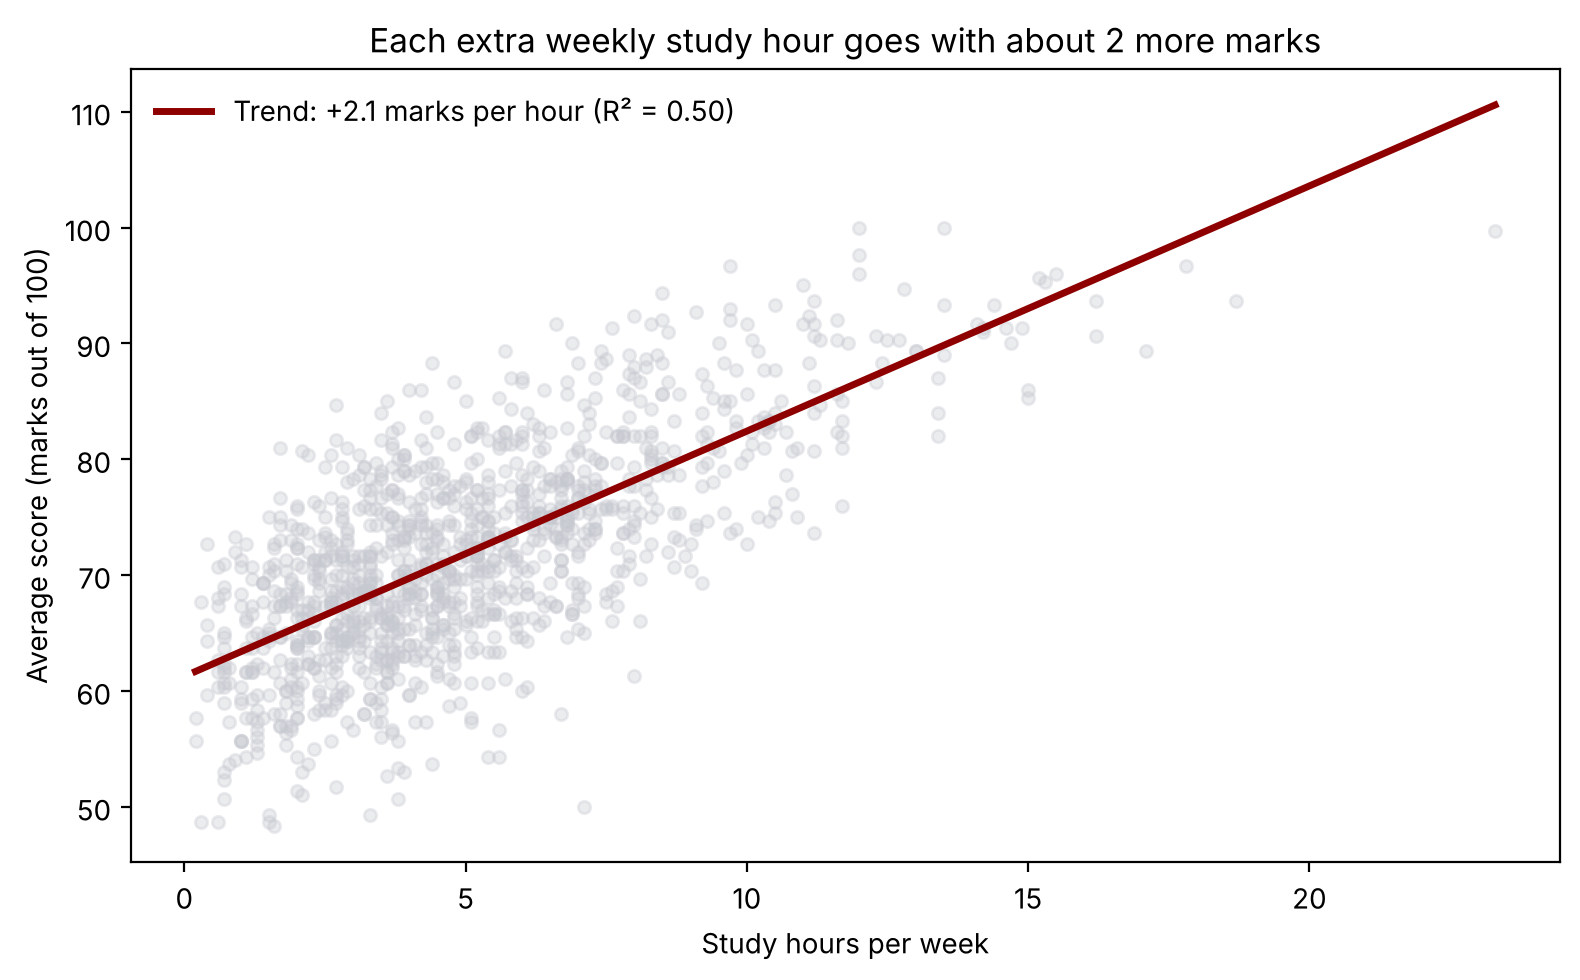

In [19]:
ax = students.plot(kind="scatter", x="study_hours", y="average_score", alpha=0.35, color="#C7C9D1", figsize=(8, 5))
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, slope * xs + intercept, color="#8E0000", linewidth=2.5,
        label=f"Trend: +{slope:.1f} marks per hour (R² = {r2:.2f})")
ax.set_title("Each extra weekly study hour goes with about 2 more marks")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Average score (marks out of 100)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/05_study_hours_trend_line.png", dpi=150)
plt.show()

**Equation:** average_score = 2.12 × study_hours + 61.26, with **R² = 0.50**.

**What the slope means:** on average, each additional hour of weekly study is associated with about **2.1 more marks** in average score, and study hours alone explain about 50% of the variation in scores.

**Limitation:** the line must not be used to predict beyond the observed range. It predicts 104 marks at 20 hours, which is impossible because marks are capped at 100, and it shows association, not causation (motivated or better-resourced learners may study more *and* score higher). The slope is stable without outliers (2.19), so the result is not driven by the few heavy studiers.

*Charts saved to `figures/`: `01_study_hours_histogram.png`, `02_avg_score_by_school_type_bar.png`, `03_avg_score_boxplot_by_school_type.png`, `04_at_risk_share_by_county_bar.png`, `05_study_hours_trend_line.png`, `06_correlation_heatmap.png`.*

## 4. Multivariate

**Question:** private-school students score higher, but is it the school or something else? First check whether the two groups differ on the other drivers, then compare like with like.

In [20]:
# Do private and public students differ on the other drivers?
students.groupby("school_type")[["attendance_rate", "study_hours"]].mean().round(2)

,attendance_rate,study_hours
school_type,,
Private,0.8,5.00
Public,0.8,5.11


In [21]:
# Segments: attendance bands (pd.cut) and study-hour quartiles (pd.qcut)
students["attendance_band"] = pd.cut(students["attendance_rate"], bins=[0, 0.7, 0.85, 1.0],
                                     labels=["Low", "Medium", "High"])
students["study_quartile"] = pd.qcut(students["study_hours"], 4, labels=["Q1", "Q2", "Q3", "Q4"])

print(students["attendance_band"].value_counts().sort_index().to_string())
print()
print("Study-hour quartile ranges (hours/week):")
print(students.groupby("study_quartile", observed=True)["study_hours"].agg(["min", "max", "count"]))

attendance_band
Low       238
Medium    499
High      463

Study-hour quartile ranges (hours/week):
                min   max  count
study_quartile                  
Q1              0.2   2.9    311
Q2              3.0   4.5    302
Q3              4.6   6.7    288
Q4              6.8  23.3    299


In [22]:
# Pivot 1: school-type gap across attendance bands
pivot_att = pd.pivot_table(students, index="attendance_band", columns="school_type",
                           values="average_score", aggfunc="mean", observed=True).round(1)
pivot_att["gap (Private - Public)"] = (pivot_att["Private"] - pivot_att["Public"]).round(1)
print(pivot_att)

# Pivot 2: school-type gap across study-hour quartiles
pivot_study = pd.pivot_table(students, index="study_quartile", columns="school_type",
                             values="average_score", aggfunc="mean", observed=True).round(1)
pivot_study["gap (Private - Public)"] = (pivot_study["Private"] - pivot_study["Public"]).round(1)
print()
print(pivot_study)

# Group sizes behind each cell (small cells deserve caution)
print()
print(pd.crosstab(students["attendance_band"], students["school_type"]))

school_type      Private  Public  gap (Private - Public)
attendance_band                                         
Low                 71.5    64.9                     6.6
Medium              75.5    69.8                     5.7
High                79.0    74.0                     5.0

school_type     Private  Public  gap (Private - Public)
study_quartile                                         
Q1                 69.5    63.8                     5.7
Q2                 74.9    67.1                     7.8
Q3                 76.2    71.2                     5.0
Q4                 83.6    80.1                     3.5

school_type      Private  Public
attendance_band                 
Low                   71     167
Medium               134     365
High                 129     334


**The gap is not explained by attendance or study time.** Private and public students are almost identical on both drivers (attendance 0.80 vs 0.80; study hours 5.00 vs 5.11 per week), and the private-school advantage persists in **every** segment:

- Across attendance bands it ranges from **5.0 to 6.6 marks** (largest among Low-attendance learners).
- Across study-hour quartiles it ranges from **3.6 to 7.8 marks**, and it is smallest in the top quartile (Q4), which is also where scores approach the 100 ceiling, so part of that narrowing may be a ceiling effect.

So the school-type gap is associated with school type itself, not with attendance or study time. We cannot say *why* (household income, teacher ratios and prior attainment are not in the data). The smallest cell (private, low attendance) has only 71 students, so single-cell gaps should not be over-read.

In [23]:
# Where is risk concentrated? At Risk share by attendance band x study quartile
risk_grid = (pd.pivot_table(students, index="attendance_band", columns="study_quartile",
                            values="at_risk", aggfunc="mean", observed=True) * 100).round(1)
print("At Risk share (%) by attendance band and study quartile:")
print(risk_grid)

print("\nAt Risk share (%) by school type:")
print((students.groupby("school_type")["at_risk"].mean() * 100).round(1))

# A simple, transparent targeting rule
low_att = students["attendance_band"] == "Low"
low_study = students["study_quartile"] == "Q1"
for name, rule in [("Low attendance AND bottom study quartile", low_att & low_study),
                   ("Low attendance OR bottom study quartile", low_att | low_study)]:
    flagged = students[rule]
    print(f"\n{name}:")
    print(f"  flags {len(flagged)} students ({len(flagged) / len(students):.1%} of all)")
    print(f"  {flagged['at_risk'].mean():.1%} of those flagged are At Risk")
    print(f"  captures {flagged['at_risk'].sum() / students['at_risk'].sum():.1%} of all At Risk learners")

At Risk share (%) by attendance band and study quartile:
study_quartile     Q1    Q2   Q3   Q4
attendance_band                      
Low              59.3  31.5  6.5  1.6
Medium           16.1   4.4  3.4  0.0
High              8.6   0.9  0.0  0.0

At Risk share (%) by school type:
school_type
Private     1.5
Public     10.9
Name: at_risk, dtype: float64

Low attendance AND bottom study quartile:
  flags 59 students (4.9% of all)
  59.3% of those flagged are At Risk
  captures 35.4% of all At Risk learners

Low attendance OR bottom study quartile:
  flags 490 students (40.8% of all)
  18.0% of those flagged are At Risk
  captures 88.9% of all At Risk learners


Risk is highly concentrated. The At Risk share is **23.9%** among low-attendance learners against **2.6%** among high-attendance learners, and **21.2%** in the lowest study-hour quartile against **0.3%** in the highest. Learners who are low on both are the most vulnerable: 59% of that group of 59 are At Risk.

## 5. Hypotheses

Patterns found, and what would be needed to test or investigate each one further. None of these is established as cause and effect by this dataset.

| # | Hypothesis (pattern seen in the data) | How it could be tested |
|---|---|---|
| H1 | More weekly study time raises scores (study hours: r = 0.70, about 2.1 marks per hour). | Pilot a structured study-support programme with a comparison group; track score change over a term. |
| H2 | Attendance protects against risk (24% At Risk when low vs 3% when high). | Compare learners before and after an attendance intervention (transport, meals, follow-up calls). |
| H3 | Private schools add value beyond attendance and study time (gap of 5.5 marks persists). | Collect household income, teacher-to-pupil ratio and prior attainment, then re-test the gap with them included. |
| H4 | County is not a driver of risk (differences within chance, p = 0.92). | Repeat with a larger sample per county or with real school-level data. |

**What this data cannot tell us:** *why* learners study less or attend less (cost, distance, home responsibilities, health), and whether the same learners improve over time, because there is one snapshot and no dates.

## Findings

**Headline:** 99 of 1,200 learners (8.2%) are At Risk, and they are concentrated in a small, identifiable group defined by how much they attend and study, not by where they live.

1. **Study hours are the strongest driver of scores.** Study hours correlate with average score at r = 0.70; the trend line shows about **2.1 more marks per extra weekly hour** (R² = 0.50). This is an association, not proof that extra study causes the gain.
2. **Risk is concentrated in low-attendance and low-study learners.** The At Risk share is 23.9% for learners attending under 70% of days against 2.6% for those above 85%, and 21.2% in the bottom study-hours quartile (under 2.9 hours a week) against 0.3% in the top quartile.
3. **Private-school students score 5.5 marks higher, and the gap is not explained by attendance or study hours.** It holds in every attendance band (5.0 to 6.6 marks) and every study quartile (3.6 to 7.8 marks). Only 1.5% of private-school learners are At Risk against 10.9% of public-school learners, and public schools hold 95% of all At Risk learners. The cause cannot be identified from this data.
4. **County and gender are poor targeting variables.** County average scores differ by only 2.1 marks and gender by 0.2. Nairobi has the highest At Risk share (9.2%), but all counties fall between 6.4% and 9.2% and the differences are consistent with chance (p = 0.92).
5. **A simple two-factor rule finds almost all At Risk learners.** Flagging learners with low attendance *or* bottom-quartile study hours covers 41% of students and captures **89% of all At Risk learners**. The narrower group with *both* risk factors is only 4.9% of students (59 learners), yet 59% of them are At Risk.

## Recommendations

1. **Target the programme by attendance and study behaviour, not by county.** Enrol learners with attendance below 70% or study time under 2.9 hours a week, and give first priority to the 59 learners who have both, where roughly 59% are already At Risk. Do not allocate funds by county, because county differences are within chance.
2. **Prioritise public schools and run the programme as a measured pilot.** Public schools hold 95% of At Risk learners, so they should receive the larger share of places. Because this data shows association only, launch with a comparison group (for example, phased roll-out) and record household income and teacher-pupil ratios, so the Director can later show what actually raised scores before scaling up the budget.

## Limitations

This analysis is **observational and uses a single snapshot** of 1,200 students, so every result describes association, not cause and effect: extra study hours or attendance may be markers of motivation, household support or school quality rather than the cause of higher scores. Important drivers are missing from the data, including household income, teacher-pupil ratios and prior attainment, so the 5.5-mark private-school gap cannot be attributed to the school itself. The dataset has no dates, so it cannot show whether learners improve or decline over time. The trend line is linear and valid only for the observed 0.2 to 23.3 hours; it predicts 104 marks at 20 hours, which is impossible because marks are capped at 100, and the capping may also narrow gaps among high scorers. County groups contain only 184 to 212 students, so small differences between counties are indistinguishable from chance. Finally, the At Risk threshold of 60 is a policy choice: moving it would change the numbers, though not the main pattern.